# Visualización de Anotaciones WSI

Este notebook permite verificar visualmente que las anotaciones de QuPath (.geojson) se están leyendo y alineando correctamente con las imágenes (.tif).

In [1]:
import os
import json
import glob
import random
import tiffslide
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from shapely.geometry import Polygon, box, shape
from pathlib import Path


# Configuración de rutas (Ajustar si es necesario)
BASE_DIR = "../"
RAW_DATA_DIR = os.path.join(BASE_DIR, "data/raw")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "annotations_resized")

# Mapeo de Colores para las clases
CLASS_COLORS = {
    "Decidual": "green",
    "Labyrinth": "blue",
    "Junctional Zone": "red",
    "dec": "green",
    "Decidua": "green"
}

def load_annotations(geojson_path):
    """Carga polígonos desde GeoJSON y los filtra por las clases definidas."""
    if not os.path.exists(geojson_path):
        print(f"Warning: Archivo no encontrado: {geojson_path}")
        return []
    
    with open(geojson_path, 'r') as f:
        data = json.load(f)
    
    polygons = []
    features = data['features']
    print('Features: ', features)
    for feature in features:
        classification = feature.get('properties', {})
        class_name = classification.get('name') if classification else None
        print('classification: ',classification)
        print('class_name: ',class_name)
        if class_name in CLASS_COLORS:
            try:
                # Usamos shape() de shapely para parsear la geometría automáticamente
                poly = shape(feature['geometry'])
                
                # Si es MultiPolygon, lo descomponemos para facilitar el manejo
                if poly.geom_type == 'MultiPolygon':
                    for p in poly.geoms:
                        polygons.append({'poly': p, 'class_name': class_name})
                else:
                    polygons.append({'poly': poly, 'class_name': class_name})
            
            except Exception as e:
                print(f"Error parseando geometría: {e}")
                    
    return polygons

In [2]:
wsi_files = glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif"))
if not wsi_files:
    raise FileNotFoundError("No se encontraron archivos .tif en la ruta especificada.")

SLIDE_INDEX = 0 
wsi_path = wsi_files[SLIDE_INDEX]
slide_name = Path(wsi_path).stem
geojson_path = os.path.join(ANNOTATIONS_DIR, f"{slide_name}.geojson")

# Carga con TiffSlide
slide = tiffslide.TiffSlide(wsi_path)
polys = load_annotations(geojson_path)

print(f"Slide: {slide_name}")
print(f"Dimensiones: {slide.dimensions} (WxH)")
print(f"Anotaciones válidas cargadas: {len(polys)}")


Features:  [{'type': 'Feature', 'id': '51a5d65d-0bd1-40ad-bc26-b5eec26c239e', 'geometry': {'type': 'MultiPolygon', 'coordinates': [[[[7945.156693114922, 5046.258305605324], [7944.6566675198355, 5046.508318402866], [7944.406654722293, 5046.508318402866], [7941.656513949321, 5049.50847197338], [7938.656360378807, 5049.50847197338], [7938.156334783721, 5049.758484770924], [7937.906321986178, 5049.758484770924], [7935.156181213207, 5052.758638341438], [7932.156027642693, 5052.758638341438], [7931.656002047606, 5053.008651138981], [7931.405989250064, 5053.008651138981], [7928.655848477092, 5056.008804709496], [7922.40552853852, 5056.008804709496], [7921.905502943435, 5056.258817507039], [7921.655490145891, 5056.258817507039], [7918.90534937292, 5059.258971077553], [7902.904530330176, 5059.258971077553], [7902.40450473509, 5059.5089838750955], [7902.154491937547, 5059.5089838750955], [7899.404351164576, 5062.509137445611], [7893.154031226004, 5062.509137445611], [7892.654005630919, 5062.7591

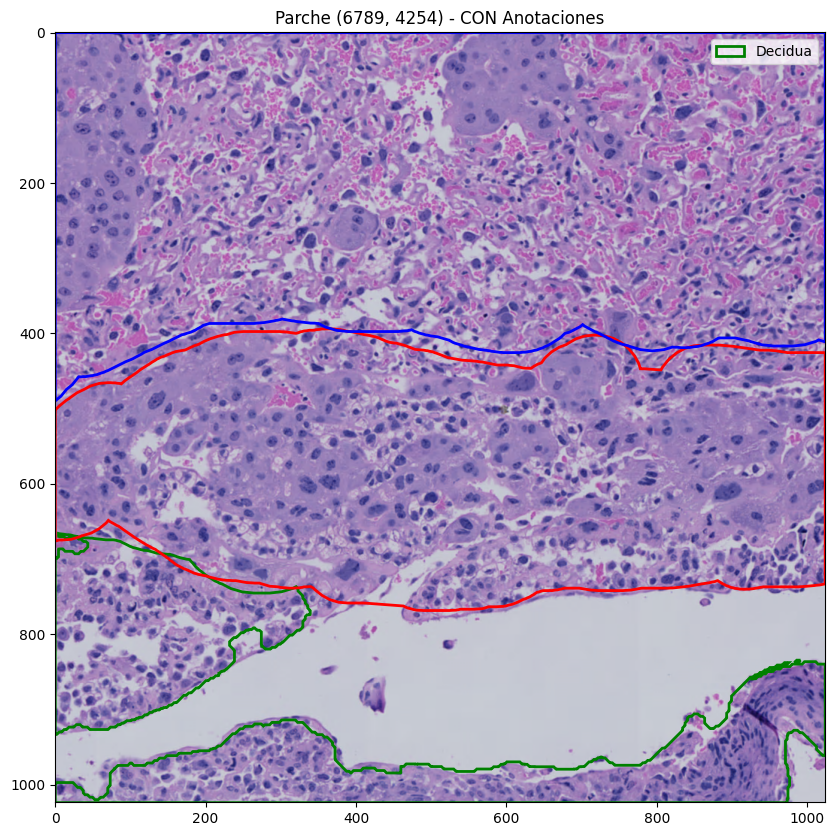

In [3]:
def view_patch(x, y, size=1024):
    """Visualiza un parche específico y sus anotaciones."""
    # 1. Extraer imagen
    region = slide.read_region((x, y), 0, (size, size)).convert("RGB")
    
    # 2. Configurar plot
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(region)
    
    # 3. Definir caja del parche en coordenadas globales
    patch_box = box(x, y, x + size, y + size)
    
    found_poly = False
    for item in polys:
        poly = item['poly']
        if patch_box.intersects(poly):
            # Intersection clip
            intersection = patch_box.intersection(poly)
            
            # Transformar a coordenadas locales del parche (0..size)
            # Restamos (x, y) de las coordenadas globales del polígono
            if not intersection.is_empty:
                if intersection.geom_type == 'Polygon':
                    parts = [intersection]
                elif intersection.geom_type == 'MultiPolygon':
                    parts = intersection.geoms
                else:
                    parts = []

                for p in parts:
                    # Extract coords
                    try:
                        xi, yi = p.exterior.xy
                        # Convert global coords to patch local coords
                        xi = [cx - x for cx in xi]
                        yi = [cy - y for cy in yi]
                        
                        # Draw
                        color = CLASS_COLORS.get(item['class_name'], 'yellow')
                        polygon_patch = patches.Polygon(list(zip(xi, yi)), 
                                                      linewidth=2, 
                                                      edgecolor=color, 
                                                      facecolor='none',
                                                      label=item['class_name'] if not found_poly else None)
                        ax.add_patch(polygon_patch)
                        found_poly = True
                    except Exception as e:
                        pass # Skip geometry errors for vis

    if found_poly:
        plt.legend()
        plt.title(f"Parche ({x}, {y}) - CON Anotaciones")
    else:
        plt.title(f"Parche ({x}, {y}) - SIN Anotaciones")
    
    plt.show()

# BUSCAR UN PARCHE CON ANOTACIONES ALEATORIO
# Intentamos 100 veces encontrar uno con intersección
import random
w_wsi, h_wsi = slide.dimensions

found = False
for _ in range(100):
    rx = random.randint(0, w_wsi - 1024)
    ry = random.randint(0, h_wsi - 1024)
    
    # Quick check
    patch_box = box(rx, ry, rx + 1024, ry + 1024)
    for item in polys:
        if patch_box.intersects(item['poly']):
            view_patch(rx, ry, size=1024)
            found = True
            break
    if found: break

if not found:
    print("No encontré un parche con anotaciones en 100 intentos aleatorios. Intenta aumentar intentos o verifica si el slide tiene anotaciones.")

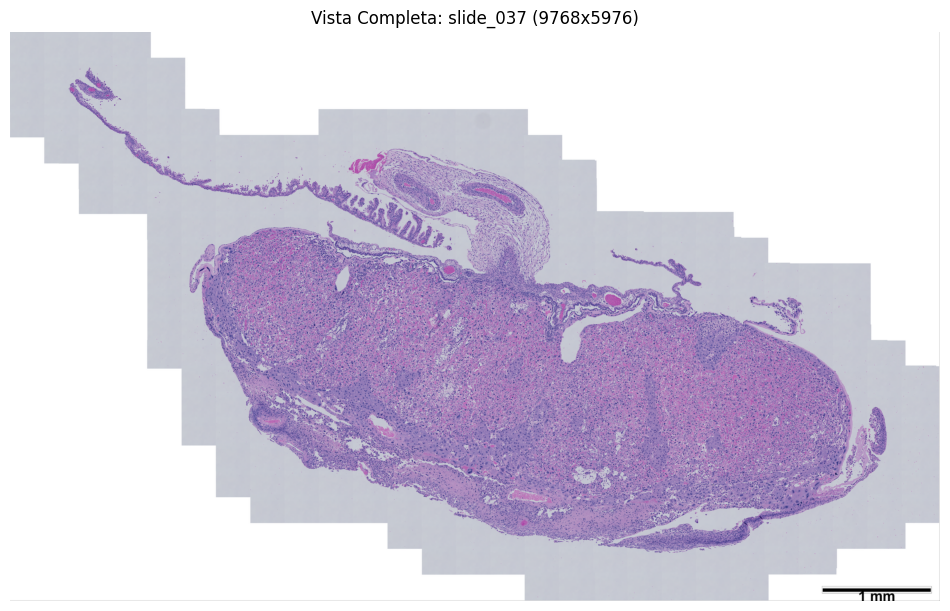

In [4]:
import matplotlib.pyplot as plt

# 1. Definir el tamaño de la miniatura que quieres ver (ej: 2000 píxeles de ancho)
target_width = 2000
scale = slide.dimensions[0] / target_width
target_height = int(slide.dimensions[1] / scale)

# 2. Obtener el thumbnail
# Esto es mucho más eficiente que cargar todo y reescalar
thumbnail = slide.get_thumbnail((target_width, target_height))

# 3. Graficar
plt.figure(figsize=(12, 8))
plt.imshow(thumbnail)
plt.title(f"Vista Completa: {slide_name} ({slide.dimensions[0]}x{slide.dimensions[1]})")
plt.axis('off')
plt.show()

Factor de escala aplicado: 0.2046


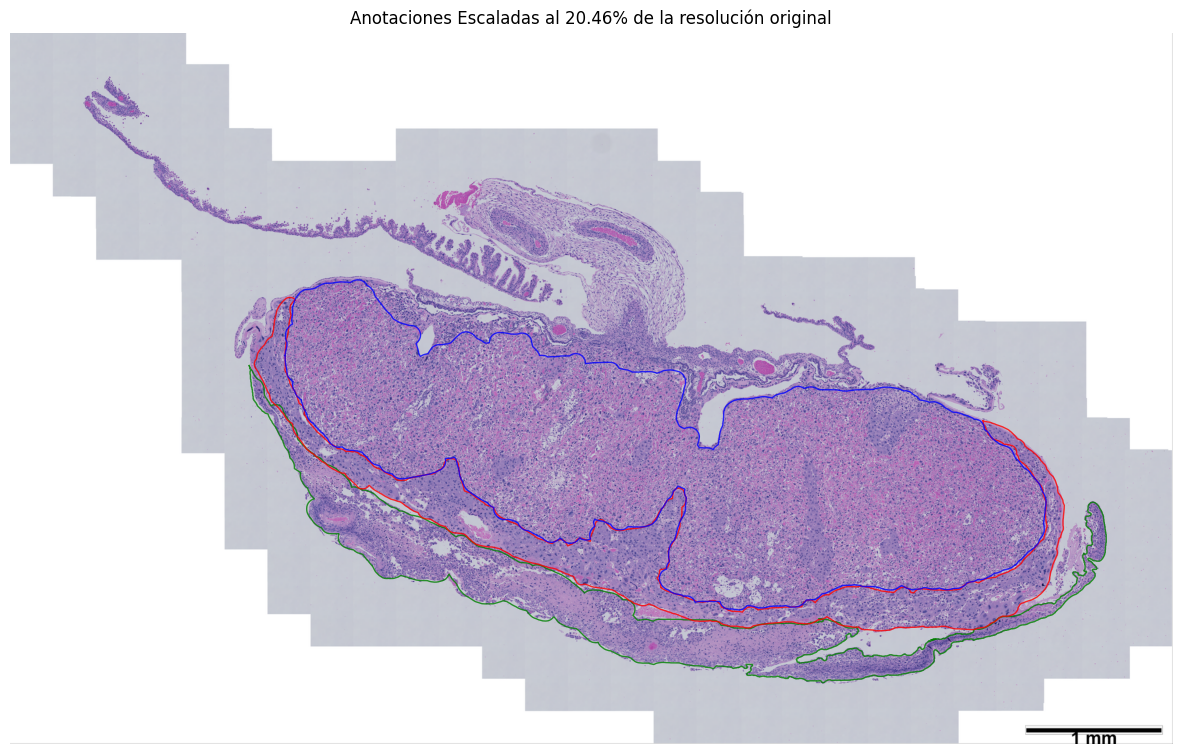

In [5]:
import matplotlib.pyplot as plt
from shapely.affinity import scale

# 1. Obtener la imagen reducida (Thumbnail)
# Supongamos que quieres verla a un ancho de 2000px
target_w = 2000
thumb = slide.get_thumbnail((target_w, int(slide.dimensions[1] * target_w / slide.dimensions[0])))
tw, th = thumb.size

# 2. Calcular el factor de escala
# QuPath usa las dimensiones originales (slide.dimensions)
real_w, real_h = slide.dimensions
factor_x = tw / real_w
factor_y = th / real_h

# Usaremos el promedio si la imagen es proporcional, 
# o escalaremos cada eje por separado.
print(f"Factor de escala aplicado: {factor_x:.4f}")

# 3. Visualizar
fig, ax = plt.subplots(figsize=(15, 10))
ax.imshow(thumb)

for item in polys:
    poly = item['poly']
    
    # ESCALADO MÁGICO CON SHAPELY
    # scale(geom, xfact, yfact, origin=(0,0))
    poly_scaled = scale(poly, xfact=factor_x, yfact=factor_y, origin=(0,0))
    
    # Dibujar el polígono reescalado
    if poly_scaled.geom_type == 'Polygon':
        x_c, y_c = poly_scaled.exterior.xy
        color = CLASS_COLORS.get(item['class_name'], 'yellow')
        ax.plot(x_c, y_c, color=color, linewidth=1, alpha=0.8)

plt.title(f"Anotaciones Escaladas al {factor_x*100:.2f}% de la resolución original")
plt.axis('off')
plt.show()

# Anotaciones reconstruidas post tiling

In [1]:
import cv2
import os
import numpy as np
import glob
import re

def reconstruct_single_wsi(image_folder, label_folder, output_path, wsi_id, img_size=1280):
    """
    Reconstruye una sola WSI basándose en un identificador en el nombre.
    """
    
    # 1. FILTRAR ARCHIVOS POR WSI_ID
    # Busca archivos que contengan el identificador (ej: _001_)
    search_pattern = f"*{wsi_id}*.jpg"
    image_files = glob.glob(os.path.join(image_folder, search_pattern))
    
    if not image_files:
        print(f"No se encontraron imágenes para el ID: {wsi_id}")
        return

    print(f"Se encontraron {len(image_files)} parches para la imagen {wsi_id}.")

    # --- FUNCIÓN DE ORDENAMIENTO ---
    def get_coords(filepath):
        filename = os.path.basename(filepath)
        numbers = re.findall(r'\d+', filename)
        if len(numbers) >= 2:
            return int(numbers[-2]), int(numbers[-1])
        return 0, 0

    # Ordenar por Y (fila) y luego X (columna)
    image_files.sort(key=lambda x: (get_coords(x)[1], get_coords(x)[0]))

    # --- 2. DETERMINAR TAMAÑO DEL LIENZO ---
    max_x = 0
    max_y = 0
    print("Analizando parches para determinar tamaño...")
    for img_path in image_files:
        x, y = get_coords(img_path)
        if x > max_x: max_x = x
        if y > max_y: max_y = y

    total_w = max_x + img_size
    total_h = max_y + img_size
    print(f"Tamaño total calculado para {wsi_id}: {total_w}x{total_h}")

    # Crear lienzo
    try:
        full_image = np.zeros((total_h, total_w, 3), dtype=np.uint8)
    except MemoryError:
        print("¡Error de memoria! La imagen es muy grande.")
        return

    # --- 3. DIBUJAR Y PEGAR ---
    colors = [(0, 255, 0), (0, 0, 255), (255, 0, 0)] # BGR

    print("Procesando parches...")
    for img_path in image_files:
        filename = os.path.basename(img_path)
        img = cv2.imread(img_path)
        if img is None: continue
        
        x_offset, y_offset = get_coords(img_path)

        # Procesar etiquetas
        label_path = os.path.join(label_folder, filename.replace('.jpg', '.txt'))
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()
                
            for line in lines:
                parts = line.split()
                if len(parts) < 5: continue
                cls = int(parts[0])
                coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                
                # Normalizar coordenadas a píxeles
                coords[:, 0] *= img_size
                coords[:, 1] *= img_size
                
                # Dibujar polígono
                cv2.polylines(img, [coords.astype(np.int32)], True, colors[cls % len(colors)], 2)
        
        # Pegar parche
        full_image[y_offset:y_offset+img_size, x_offset:x_offset+img_size] = img

    # 4. Guardar
    print(f"Guardando imagen final en {output_path}...")
    cv2.imwrite(output_path, full_image)
    print("¡Hecho!")

# --- USO ---
IMAGE_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-STRATIFIED-H_NEGATIVE-1280-035ovlp/train/images"
LABEL_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-STRATIFIED-H_NEGATIVE-1280-035ovlp/train/labels"

# Definir el ID de la lámina que quieres reconstruir
WSI_IDENTIFIER = "001" 
OUTPUT_FILE = f"reconstruccion_wsi_strat_h_negative_{WSI_IDENTIFIER}.jpg"

reconstruct_single_wsi(IMAGE_DIR, LABEL_DIR, OUTPUT_FILE, WSI_IDENTIFIER)

Se encontraron 161 parches para la imagen 001.
Analizando parches para determinar tamaño...
Tamaño total calculado para 001: 1344x4482
Procesando parches...
Guardando imagen final en reconstruccion_wsi_strat_h_negative_001.jpg...
¡Hecho!


# VISUALIZACIÓN DATASET

In [2]:
# Visualize Dataset
import cv2
import os
import glob
import numpy as np

def visualize_dataset(image_folder, label_folder, output_folder, img_size=1024):
    """
    Lee imágenes y etiquetas YOLO, dibuja los polígonos y guarda el resultado.
    """
    
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)
        
    image_files = glob.glob(os.path.join(image_folder, "*.jpg"))
    
    # Colores para las clases (BGR) - Puedes añadir más si tienes más de 3
    colors = {
        0: (0, 255, 0),   # Clase 0: Verde
        1: (0, 0, 255),   # Clase 1: Rojo
        2: (255, 0, 0),   # Clase 2: Azul
        3: (0, 255, 255)  # Clase 3: Amarillo
    }

    print(f"Procesando {len(image_files)} imágenes...")

    for img_path in image_files:
        filename = os.path.basename(img_path)
        img = cv2.imread(img_path)
        
        if img is None:
            print(f"Error al leer: {filename}")
            continue
            
        label_path = os.path.join(label_folder, filename.replace('.jpg', '.txt'))
        
        if os.path.exists(label_path):
            with open(label_path, 'r') as f:
                lines = f.readlines()
                
            for line in lines:
                parts = line.split()
                if len(parts) < 5: continue
                
                cls = int(parts[0])
                # Polígonos normalizados: x1, y1, x2, y2...
                coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                
                # Convertir coordenadas normalizadas a píxeles
                coords[:, 0] *= img.shape[1] # ancho
                coords[:, 1] *= img.shape[0] # alto
                
                # Dibujar polígono
                color = colors.get(cls, (255, 255, 255))
                cv2.polylines(img, [coords.astype(np.int32)], True, color, thickness=2)
                
                # Opcional: Escribir el número de clase
                cv2.putText(img, str(cls), (int(coords[0,0]), int(coords[0,1])), 
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)
        
        # Guardar imagen resultante
        output_path = os.path.join(output_folder, filename)
        cv2.imwrite(output_path, img)

    print(f"Visualización guardada en: {output_folder}")

# --- CONFIGURACIÓN DE RUTAS ---
# Ajusta estas rutas a las de tu proyecto
IMAGE_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-STRATIFIED-H_NEGATIVE-1280-035ovlp/train/images"
LABEL_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-STRATIFIED-H_NEGATIVE-1280-035ovlp/train/labels"
OUTPUT_DIR = "visualizacion_etiquetas"

visualize_dataset(IMAGE_DIR, LABEL_DIR, OUTPUT_DIR)


Procesando 3209 imágenes...


KeyboardInterrupt: 

In [ ]:
from PIL import Image, ImageDraw
from shapely.geometry import shape
from shapely.ops import unary_union
from shapely.validation import make_valid
from shapely.geometry import Polygon, MultiPolygon, GeometryCollection
from glob import glob
import json
path_image = '/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/wsi_splitted/test/*.tif'
images_paths = glob(path_image)
try:
    for image_path in images_paths:
        gt_by_class = {}
        name = image_path.split('/')[-1].split('.')[0]
        annot_path = f'/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annotations_resized/{name}.geojson'
        img = Image.open(image_path).convert("RGB")
        gt_overlay = img.copy()
        draw_gt = ImageDraw.Draw(gt_overlay, "RGBA")

        name_to_id = {
            "Decidual": 0,
            "Decidua": 0,
            'dec': 0,
            "Labyrinth": 1,
            'lab': 1,
            'lab1': 1,
            'lab2': 1,
            'jz': 2,
            'Junctional': 2,
            'Junctional zone': 2,
            'jz1': 2,
            'jz2': 2,
            "Junctional Zone": 2,
        }
        colores = {
            0: (255, 0, 0, 100), # Rojo - Decidual/Decidua 
            1: (0, 255, 0, 100), # Verde - Labyrinth
            2: (0, 0, 255, 100), # Azul - Junctional Zone
            3: (255, 255, 0, 100),
        }
        with open(annot_path) as f:
            data = json.load(f)

        print('class_names: ', data.get('features'))
        for feature in data.get("features", []):
            geom = make_valid(shape(feature["geometry"]))
            class_name = feature["properties"].get("name")
            class_id = name_to_id[class_name]

            if geom.is_empty:
                continue

            gt_by_class.setdefault(class_id, []).append(geom)

            if geom.geom_type == "Polygon":
                draw_gt.polygon(list(geom.exterior.coords),
                                fill=colores.get(class_id, (128,128,128,100)))

            if geom.geom_type == 'MultiPolygon':
                for poly in geom.geoms:
                    draw_gt.polygon(list(poly.exterior.coords),
                                    fill=colores.get(class_id, (128,128,128,100)))

        display(gt_overlay)
except Exception as e:
    print(f"Error al procesar la imagen: {e}")